# AMD-DBSCAN

## Understanding DBSCAN
`AMD-DBSCAN` is essentially a modified version of a normal `DBSCAN`, so understanding the normal `DBSCAN` is essential to understanding `AMD-DBSCAN`.

The goal of a `dbscan` is to cluster data points on a graph.

Before going over how the algorithm works lets name the parameters that it takes in:
- `Epsilon` - The range in which we look for neighboring data points.
- `MinPts` - The amount of neighbors a point needs to be a **Core Point**.

`dbscan` works in the following way:
- Loop over all points:
    - For each point find the amount of neighboring points it has within range `Epsilon`.
    - Assign the point a type based on the result of the previous procedure:
        - **Core Point** - The point has at least `MinPts` neighbors.
        - **Border Point** - The point isn't a **Core Point**, but has one as it's neighbor.
        - **Noise Point** - The point is neither of the previous points.
- Start with a random **Core Point**.
- Assign it to the first cluster.
- Add all neighboring **Core Points** and **Border Points** to the same cluster and repeat with them.
- Start a new cluster with an unassigned **Core Point** and repeat the previous steps.

**IMPORTANT** - The point itself counts as its own neighbor.

In [91]:
from enum import Enum

# Declare the DBSCAN parameters
epsilon = 5000.0
minpts = 3

# Declare the data types we will use
class PointType(Enum):
    CORE = 1
    BORDER = 2
    NOISE = 3

class Point:
    def __init__(self, coordinates):
        self.cluster_id = 0
        self.coordinates = coordinates
        self.type = PointType.NOISE

## Calculating Distance
We need a distance function that will work for any given number of dimensions. Luckily such a function exists and is called the **Euclidean distance** function.

$d(A,B)=\sqrt{\sum_{i=1}^{n}(A_i-B_i)^2}$

To implement it in `python` we would do the following:

In [92]:
import math

def euclidean_distance(a, b):
    if len(a.coordinates) != len(b.coordinates):
        raise ValueError("Dimensions of datapoints must match!")
    
    return math.sqrt(
        sum((x - y) ** 2 for x, y in zip(a.coordinates, b.coordinates))
    )

## Finding Neighbors
Now that we can calculate the distance, we need to create a function that will return a points neighbors.

We will also cache the neighbors list, so that we don't need to recalculate it when we visit the same point twice.

In [93]:
neighbors_cache = {}

def get_neighbors(points, point):
    if point in neighbors_cache:
        return neighbors_cache[point]

    neighbors = []
    for other in points:
        if euclidean_distance(point, other) <= epsilon:
            neighbors.append(other)
    
    neighbors_cache[point] = neighbors
    return neighbors

def is_core(points, point):
    return len(get_neighbors(points, point)) >= minpts

## Importing the data
Before being able to see our `dbscan` in action we will need to import some suitable data.

For now we will use the `Locations.txt` dataset from the `AMD-DBSCAN` study, since it's has two dimensions and will be easy to display on a graph.

In [94]:
import csv

points = []

with open("AMD-DBSCAN/dataset/Locations.txt", "r") as file:
    reader = csv.reader(file)

    for row in reader:
        coordinates = [float(value) for value in row]
        points.append(Point(coordinates))

## Creating the clusters
Now we will apply what we described in the previous sections and extract the clusters from the dataset.

**Important**
In a real-world implementation, we would probably want to segment the data space and only check the points that are in neighboring segments. This could be done with a structure called a **Spatial Hash Grid**.

We will NOT use this approach, since we don't want to complicate the implementation and obfuscate the core topic of a `DBSCAN`.

If you're creating a real implementation you probably don't want every point to check every other point in the distance calculation...

In [95]:
# Find the first core point:
i = 0
current_cluster_id = 0

while i < len(points):
    point = points[i]

    if is_core(points, point) == False or point.cluster_id != 0:
        i += 1
        continue

    current_cluster_id += 1
    point.cluster_id = current_cluster_id

    queue = get_neighbors(points, points[i])

    while queue:
        neighbor = queue.pop()

        # If the neighbor is not assigned
        if neighbor.cluster_id == 0:
            neighbor.cluster_id = current_cluster_id
            nn = get_neighbors(points, neighbor)
            if len(nn) >= minpts:
                neighbor.type = PointType.CORE
                queue.extend(nn)

## Displaying the resulting clusters


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


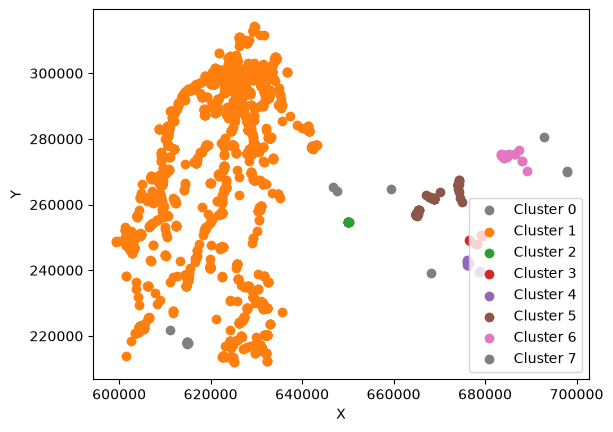

In [96]:
%pip install matplotlib
import matplotlib.pyplot as plt

cluster_ids = sorted({point.cluster_id for point in points})
cmap = plt.get_cmap("tab10")
colors = {
    cluster_id: ("gray" if cluster_id == 0 else cmap(i % 10))
    for i, cluster_id in enumerate(cluster_ids)
}

for cluster_id in cluster_ids:
    cluster_points = [
        point.coordinates for point in points
        if point.cluster_id == cluster_id
    ]
    plt.scatter(
        [coords[0] for coords in cluster_points],
        [coords[1] for coords in cluster_points],
        color=colors[cluster_id],
        label=f"Cluster {cluster_id}",
    )

plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

## Understanding AMD-DBSCAN